# TP2 · Darija-Sentiment · nouvelle campagne A–G

**Notebook préparé, non exécuté. Aucun nouveau score n'est disponible avant votre exécution.**

Le sentiment marocain `ary` est la tâche principale : négatif, neutre, positif. Le corpus algérien
`arq/train` intervient **uniquement dans E2**, avec une seconde tête sur le même encodeur.
Les partitions officielles ary restent intactes. Les exemples pédagogiques ne sont pas ajoutés au train.

**Démarrage :** importer ce notebook avec Python 3.10–3.13, lire les options au début
de la première cellule, puis exécuter dans l'ordre. Le code et les données ary sont incorporés : même
importé seul, le notebook peut les restaurer dans un dossier inscriptible. Le démarrage installe
les dépendances manquantes/incompatibles à l'étape 1.5 si `INSTALL_DEPENDENCIES=True`. Un redémarrage de session peut
être nécessaire une fois si pip remplace des bibliothèques déjà chargées. La section 2 vérifie les
imports, les données, CUDA, AraVec et l'accès aux configurations des modèles avant les entraînements.
AraVec peut être téléchargé automatiquement depuis sa source officielle et ses trois fichiers sont
vérifiés par SHA-256 ; les poids des autres modèles sont téléchargés lors de leur utilisation.
Une connexion Internet reste nécessaire si ces ressources ne sont pas déjà disponibles.
Python 3.10–3.13 accepte NumPy 1 ou 2 avec Gensim 4.4 : les versions compatibles de NumPy,
SciPy et PyTorch du runtime sont conservées. Installer seulement un module non chargé ne demande
pas de redémarrage. Si une bibliothèque chargée est remplacée, reprendre après un vrai redémarrage ;
réexécuter la cellule seule ne suffit pas.

**Sorties :** `experiments/campaign_v3/`, séparées de `results/` et `models/` historiques.
Les notebooks historiques et leur HTML sont conservés sous le suffixe `_historique`.
Un nouveau nom de campagne est requis si le code ou les hyperparamètres changent après le démarrage.
Un run terminé est repris sans réentraînement ; un run interrompu avant sauvegarde est recommencé.

**Protocole :** train apprend ; val (= dev) choisit les variantes, les époques et les décalages multiclasse ;
test est ouvert après vérification de toutes les parties et verrouillage. Les trois graines sont 42/43/44.
Le représentant est toujours 42. Weighted-F1 assure la comparaison AfriSenti ; Macro-F1 et scores par écriture
complètent l'analyse. B utilise des modèles fixes : une seule exécution déterministe par variante.

**Limite de cette refonte :** le test ary a déjà été observé dans l'étude historique. Les résultats de cette
nouvelle campagne seront des réévaluations exploratoires, même si aucun réglage automatique n'utilise ses labels.
Une confirmation indépendante exige de nouveaux exemples annotés. Aucun meilleur score n'est garanti.

Sources : [AfriSenti](https://aclanthology.org/2023.emnlp-main.862/),
[SemEval-2023 Task 12](https://aclanthology.org/2023.semeval-1.315/),
[DarijaBERT](https://doi.org/10.1007/s41060-023-00498-2),
[fastText](https://aclanthology.org/Q17-1010/).

## 1.1 · Imports et options

**Objectif :** Définir les options sans installation ni téléchargement.

**Méthode et interprétation :** Exécuter les étapes 1.1 à 1.5 une par une. Si une étape échoue, son titre indique le bloc concerné ; ne pas poursuivre avant de résoudre l'erreur.

In [1]:
from pathlib import Path
from types import SimpleNamespace
from zipfile import ZipFile
import os, sys, base64, hashlib, io

# Options à modifier avant de lancer le notebook.
PROJECT_DIR = os.environ.get("DARIJA_PROJECT_DIR", "")
CAMPAIGN_NAME = "campaign_v3"
OUTPUT_DIR = ""  # Facultatif : dossier persistant, par exemple sur Drive.
INSTALL_DEPENDENCIES = True
AUTO_DOWNLOAD_ARAVEC = True
CHECK_MODEL_ACCESS = True
RUN_TRAINING = True
RUN_FINAL_EVALUATION = True
DEVICE = "auto"
ARAVEC_PATH = ""
CONFIG_OVERRIDES = {}  # {"micro_batch_e": 1} si la mémoire GPU est insuffisante.
print("[1/5] Options chargées — Python", sys.version.split()[0])

[1/5] Options chargées — Python 3.13.16


## 1.2 · Vérifier l'archive intégrée

**Objectif :** Contrôler l'intégrité du code et des données.

**Méthode et interprétation :** Cette étape ne lance pas pip. Une erreur ici concerne l'archive, son empreinte ou le chargement des utilitaires.

In [2]:
# Code et données intégrés : conserver ces deux lignes.
EMBEDDED_PROJECT_SHA256 = '74a6d8e029573fcb63a89be85e21d0aa909085a98bdea9c85f3992ac5a8b234e'
EMBEDDED_PROJECT = '...'

# Charger les utilitaires depuis l'archive vérifiée.
payload = base64.b64decode(EMBEDDED_PROJECT, validate=True)
if hashlib.sha256(payload).hexdigest() != EMBEDDED_PROJECT_SHA256:
    raise ValueError("Archive endommagée : réimporter le notebook.")
setup = SimpleNamespace()
with ZipFile(io.BytesIO(payload)) as archive:
    exec(compile(archive.read("scripts/notebook_bootstrap.py"), "notebook_bootstrap.py", "exec"), vars(setup))
print("[2/5] Archive vérifiée et utilitaires chargés")

[2/5] Archive vérifiée et utilitaires chargés


## 1.3 · Restaurer le projet

**Objectif :** Trouver ou restaurer les fichiers du projet.

**Méthode et interprétation :** Une erreur ici concerne PROJECT_DIR, la restauration des fichiers ou les droits d'accès. Aucune bibliothèque n'est installée.

In [3]:
PROJECT = setup.bootstrap_project(EMBEDDED_PROJECT, EMBEDDED_PROJECT_SHA256, PROJECT_DIR)
print("[3/5] Projet disponible :", PROJECT)

Code et données restaurés depuis le notebook : /content/Darija-Sentiment-runtime-74a6d8e029
[3/5] Projet disponible : /content/Darija-Sentiment-runtime-74a6d8e029


## 1.4 · Préparer les résultats

**Objectif :** Vérifier le nom de campagne et le dossier de sortie.

**Méthode et interprétation :** Une erreur ici concerne CAMPAIGN_NAME ou OUTPUT_DIR. Choisir un dossier inscriptible ; les résultats existants sont conservés.

In [4]:
if Path(CAMPAIGN_NAME).name != CAMPAIGN_NAME or CAMPAIGN_NAME in {"", ".", ".."} or "\\" in CAMPAIGN_NAME:
    raise ValueError("CAMPAIGN_NAME doit être un simple nom de dossier.")
OUTPUT = (Path(OUTPUT_DIR).expanduser() if OUTPUT_DIR else PROJECT / "experiments" / CAMPAIGN_NAME).resolve()
if not setup.writable_directory(OUTPUT):
    raise PermissionError(f"Dossier non inscriptible : {OUTPUT}. Modifier OUTPUT_DIR.")
print("[4/5] Dossier de résultats accessible :", OUTPUT)

[4/5] Dossier de résultats accessible : /content/Darija-Sentiment-runtime-74a6d8e029/experiments/campaign_v3


## 1.5 · Vérifier et installer les dépendances

**Objectif :** Isoler la vérification des versions et l'installation pip.

**Méthode et interprétation :** Le message de redémarrage reçu précédemment provient de cette étape. Si des bibliothèques chargées sont remplacées, redémarrer la session et reprendre à 1.1. En cas d'échec pip, lire ses lignes ERROR au-dessus du traceback.

In [5]:
print("[5/5] Vérification des dépendances — installation autorisée :", INSTALL_DEPENDENCIES)
setup.ensure_dependencies(PROJECT, install=INSTALL_DEPENDENCIES)
print("[5/5] Dépendances prêtes. Continuer avec la section 2 : configuration et ressources.")

[5/5] Vérification des dépendances — installation autorisée : True
Préparation des dépendances dans /usr/bin/python3 : transformers, gensim
[5/5] Dépendances prêtes. Continuer avec la section 2 : configuration et ressources.


## 2 - Configuration et verification des ressources

**Objectif :** Verifier les ressources avant A.

**Méthode et interprétation :** Adapter les options de la cellule 1. Les fichiers AraVec manquants sont telecharges et verifies avant la campagne, ainsi que l'acces aux configurations des modeles. Les poids complets restent charges au moment de leur utilisation.

In [6]:
"""Bloc de configuration inséré dans le notebook après l'amorçage stdlib."""
import json, html

os.environ["DARIJA_OUTPUT_ROOT"] = str(OUTPUT)
os.environ["DARIJA_CLEANING"] = "conservative_v2"
os.environ["DARIJA_MAX_LENGTH"] = str(CONFIG_OVERRIDES.get("max_length", 128))
current_sources = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in (PROJECT / "src").glob("*.py")}
loaded = sys.modules.get("src.preprocess")
if loaded is not None:
    if (Path(loaded.__file__).resolve().parent.parent != PROJECT
            or loaded.ROOT != OUTPUT or loaded.CLEANING != "conservative_v2"
            or globals().get("_DARIJA_IMPORTED_SOURCE_HASHES") != current_sources):
        raise RuntimeError("Projet, code ou sortie différents dans ce kernel. Redémarrer la session puis exécuter depuis la première cellule.")
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
try:
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import torch
    from IPython.display import display, Markdown, HTML, Image
    from src import campaign
    from src.preprocess import ROOT, LABELS, download_data, load_split, audit_data, tokens, build_vocab, encode_texts
    from src.evaluate import results_table, select_on_dev, attention_examples, plot_histories, by_script, decide
    from src.train import runtime_info, load_predictor
    from src.resources import preflight
except Exception as error:
    raise RuntimeError(f"Import impossible : {error}. Installer requirements-notebook.txt dans ce kernel, redémarrer la session et relancer depuis le début.") from error
_DARIJA_IMPORTED_SOURCE_HASHES = current_sources
CONFIG = campaign.default_config()
CONFIG.update(CONFIG_OVERRIDES)
if DEVICE != "auto":
    CONFIG["device"] = DEVICE
if ARAVEC_PATH:
    CONFIG["aravec_path"] = ARAVEC_PATH
CONFIG["aravec_path"] = str(Path(CONFIG["aravec_path"]).expanduser().resolve())
os.environ["DARIJA_EVAL_DEVICE"] = CONFIG["device"]
campaign.prepare(CONFIG, dry_run=True)
if RUN_TRAINING:
    resource_report = preflight(CONFIG, check_models=CHECK_MODEL_ACCESS, download_aravec=AUTO_DOWNLOAD_ARAVEC)
    display(pd.Series(resource_report).to_frame("Ressources vérifiées avant A"))
    if CONFIG["include_e2"]:
        campaign.auxiliary_train()  # Vérifier arq dès le départ ; aucune tâche n'est entraînée ici.
manifest = campaign.prepare(CONFIG)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
COLORS = ["#b65b54", "#87958b", "#1f6755"]


def show_file(name, limit=30):
    path = ROOT / "results" / name
    if not path.exists():
        print("Non exécuté :", name)
        return pd.DataFrame()
    frame = pd.read_csv(path)
    display(frame.head(limit))
    return frame


def show_attention(frame):
    if frame.empty:
        print("Pas de checkpoint attention disponible.")
        return
    for example, group in frame.groupby("example", sort=False):
        maximum = max(group.attention.max(), 1e-12)
        line = " ".join(f'<span title="{r.attention:.4f}" style="background:rgba(31,103,85,{0.08+0.65*r.attention/maximum:.3f});padding:3px">{html.escape(r.token)}</span>' for r in group.itertuples())
        display(HTML(f'<p><b>{html.escape(str(example))}</b></p><p dir="auto" style="line-height:2.5">{line}</p>'))


def dev_summary(family=None):
    table = results_table()
    if table.empty:
        print("Aucun résultat : exécuter les entraînements.")
        return pd.DataFrame()
    table = table.loc[table.split.eq("dev") & table.decision.eq("dev_offsets") & table.purpose.eq("benchmark")]
    if family:
        table = table.loc[table.family.eq(family)]
    summary = table.groupby(["family", "variant"]).agg(weighted_f1=("weighted_f1", "mean"), macro_f1=("macro_f1", "mean"), std=("weighted_f1", "std"), graines=("seed", "nunique"), secondes=("train_seconds", "mean")).reset_index()
    return summary.sort_values("weighted_f1", ascending=False)


def after_test():
    if not (ROOT / "results/comparison.csv").exists():
        raise RuntimeError("Exécuter la cellule de verrouillage et d'évaluation finale avant cette analyse.")


display(pd.Series(CONFIG, name="Configuration figée après contrôle").to_frame())
display(pd.Series(runtime_info()).to_frame("Runtime"))
print("Projet :", PROJECT, "\nSorties :", ROOT)
print("GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

AraVec absent : téléchargement officiel avant la campagne (~1 Gio une fois extrait).
Téléchargement full_uni_cbow_100_twitter.zip : 64 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 128 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 192 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 256 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 320 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 384 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 448 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 512 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 576 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 640 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 704 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 768 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 832 Mio
Téléchargement full_uni_cbow_100_twitter.zip : 896 Mio


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


config.json:   0%|          | 0.00/779 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/787 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

,Ressources vérifiées avant A
data_files,6
aravec,/content/Darija-Sentiment-runtime-74a6d8e029/m...
device,cuda
free_disk_gib,111.269855
model_configs_checked,True
note,"Configurations accessibles ; poids complets, e..."


,Configuration figée après contrôle
seeds,"[42, 43, 44]"
device,cuda
max_length,128
char_length,512
c_epochs,15
d_epochs,10
e_epochs,5
micro_batch_e,2
c_grid_a,"[0.25, 1.0, 4.0]"
lambdas,"[0.1, 0.3, 0.7]"


,Runtime
python,3.13.16
torch,2.11.0+cu130
cuda,True
cpu_threads,2
ram_gb,12.671406
available_ram_gb,11.054989
packages,"{'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-..."


Projet : /content/Darija-Sentiment-runtime-74a6d8e029 
Sorties : /content/Darija-Sentiment-runtime-74a6d8e029/experiments/campaign_v3
GPU : Tesla T4


## 3 · Audit des partitions

**Objectif :** Repérer doublons et collisions sans labels test.

**Méthode et interprétation :** Les fichiers officiels ne sont pas modifiés. Le test chargé ici contient uniquement ses textes ; les contradictions incluant ses labels sont étudiées après verrouillage.

In [7]:
train, dev, test_texts = [load_split(s) for s in ("train", "dev", "test")]
counts, collisions, conflicts = audit_data()
display(counts); display(collisions); display(conflicts)
assert "label" not in test_texts

,split,n,expected,raw_duplicates,clean_duplicates
0,train,5583,5583,20,20
1,dev,494,494,0,0
2,test,2961,2961,0,0


,split_a,split_b,text
0,train,dev,بﻻدي ومنبع أجدادي أفتخر بها أينما دهبت روعة من...
1,train,dev,كتحلموا اغلبية الشعب سيصوت على هدا الرجل '


""


## 4 · Lire les tweets

**Objectif :** Comprendre arabe, latin et mélange d'écritures.

**Méthode et interprétation :** Une écriture latine peut contenir du français ou de l'Arabizi ; ce détecteur n'identifie pas la langue. Nettoyage v2 : retirer URLs/mentions, conserver négation, accents, emojis, chiffres et répétitions.

In [8]:
for script, group in train.groupby("script"):
    display(group[["row_id", "tweet", "text", "label"]].head(3).assign(ecriture=script))

,row_id,tweet,text,label,ecriture
2,ary:train:2,: أتفهم العثماني وأتفهم الجدل الشعبي. الحل: حا...,: أتفهم العثماني وأتفهم الجدل الشعبي. الحل: حا...,neutral,arabic
3,ary:train:3,كان افظل حاكم عربي',كان افظل حاكم عربي',positive,arabic
4,ary:train:4,ماريانو راخوي : خاص المغرب واسبانيا يشرحو للرأ...,ماريانو راخوي : خاص المغرب واسبانيا يشرحو للرأ...,neutral,arabic


,row_id,tweet,text,label,ecriture
0,ary:train:0,hhhhhhhhhhhhhhhhhhhhhh ana ga3ma sma3tt ach ka...,hhhhhhhhhhhhhhhhhhhhhh ana ga3ma sma3tt ach ka...,neutral,latin
1,ary:train:1,hhhh hardart jomhorha la fi3lan kadahko lach m...,hhhh hardart jomhorha la fi3lan kadahko lach m...,neutral,latin
7,ary:train:7,dakchi alach hamdoulah mereta7 et en bonne san...,dakchi alach hamdoulah mereta7 et en bonne san...,positive,latin


,row_id,tweet,text,label,ecriture
101,ary:train:101,أزمة “أساتذة الكونطرا”.. بنموسى: حققنا ليهم عد...,أزمة “أساتذة الكونطرا”.. بنموسى: حققنا ليهم عد...,neutral,mixed
585,ary:train:585,وانا كنgولو سير الله يعطيك العمى وطولان العمر ...,وانا كنgولو سير الله يعطيك العمى وطولان العمر ...,negative,mixed
748,ary:train:748,سير شوف رجال الدولة ديال بصح a zb,سير شوف رجال الدولة ديال بصح a zb,negative,mixed


,row_id,tweet,text,label,ecriture
5239,ary:train:5239,ﻧﺤﺘﺮﻡ ﻓﻴﻚ ﺍﻷﺧﻼﻕ .',ﻧﺤﺘﺮﻡ ﻓﻴﻚ ﺍﻷﺧﻼﻕ .',positive,other


## A.1 · Distribution des labels

**Objectif :** Afficher les effectifs et proportions par écriture.

**Méthode et interprétation :** Le global et les sous-groupes répondent à deux questions différentes. Les distributions test seront ajoutées en F1 après verrouillage.

,split,script,label,n,proportion
0,train,global,negative,1664,0.298048
1,train,global,neutral,2161,0.387068
2,train,global,positive,1758,0.314884
3,train,arabic,negative,1137,0.348239
4,train,arabic,neutral,954,0.292190
5,train,arabic,positive,1174,0.359571
6,train,latin,negative,514,0.225835
7,train,latin,neutral,1190,0.522847
8,train,latin,positive,572,0.251318
9,train,mixed,negative,13,0.317073


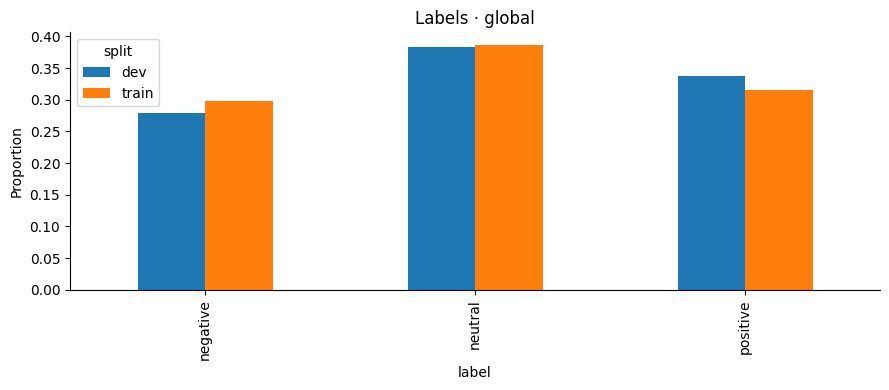

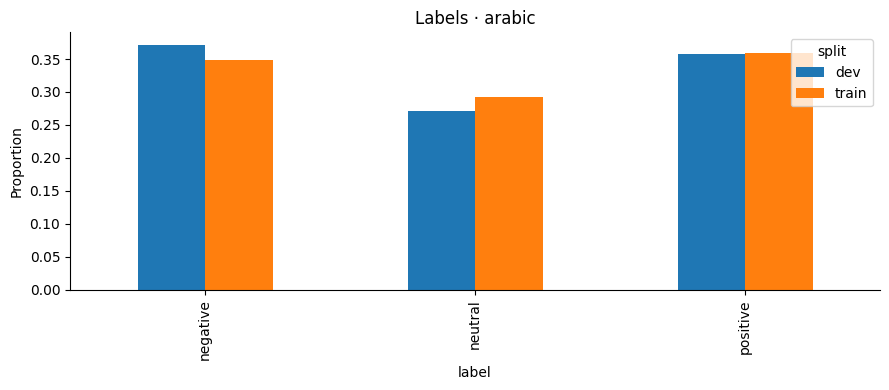

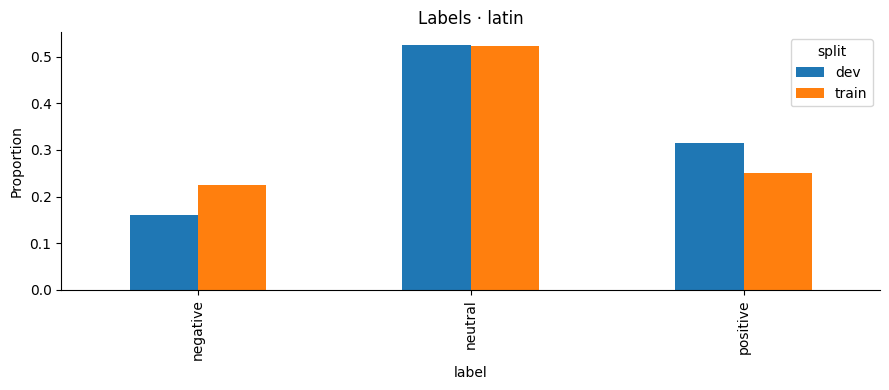

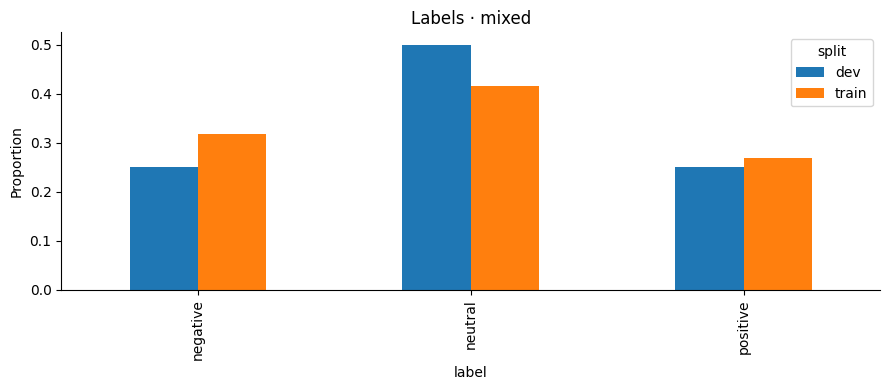

In [9]:
distribution = campaign.distributions()
display(distribution)
for script in ["global", "arabic", "latin", "mixed"]:
    part = distribution.loc[distribution.script.eq(script)]
    if not part.empty:
        part.pivot(index="label", columns="split", values="proportion").reindex(LABELS).plot.bar(title=f"Labels · {script}")
        plt.ylabel("Proportion"); plt.tight_layout(); plt.show()

## A.2 · Longueurs et troncature

**Objectif :** Mesurer les informations susceptibles d'être tronquées.

**Méthode et interprétation :** Les longueurs regex ne sont pas les longueurs WordPiece. Les limites sont fixées avant test : 128 tokens C/D/E, 512 caractères C4. TF-IDF utilise le texte complet.

token_count                                                 \
                   count       mean        std   min    25%   50%   75%   
split script                                                              
dev   arabic       277.0  16.472924  10.231566   3.0   9.00  16.0  21.0   
      latin        213.0  13.107981   7.134991   4.0   8.00  12.0  17.0   
      mixed          4.0  16.750000   6.130525  11.0  11.75  16.5  21.5   
train arabic      3265.0  15.690965   9.345479   1.0   9.00  15.0  21.0   
      latin       2276.0  12.843585   6.405777   2.0   8.00  12.0  17.0   
      mixed         41.0  19.073171   7.994968   6.0  15.00  17.0  24.0   
      other          1.0   5.000000        NaN   5.0   5.00   5.0   5.0   

                    char_count                                          \
                max      count       mean        std   min   25%   50%   
split script                                                             
dev   arabic   85.0      277.0  81.249097  50.661845  10.0  44.0  76.0   
      latin    67.0      213.0  71.901408  35.585993  16.0  43.0  64.0   
      mixed    23.0        4.0  80.750000  20.854656  59.0  65.0  81.5   
train arabic  120.0     3265.0  77.804594  47.356444   4.0  42.0  73.0   
      latin    77.0     2276.0  71.460896  34.369815  13.0  44.0  67.0   
      mixed    47.0       41.0  97.634146  41.492021  33.0  73.0  94.0   
      other     5.0        1.0  18.000000        NaN  18.0  18.0  18.0   

                             
                 75%    max  
split script                 
dev   arabic  111.00  389.0  
      latin    98.00  251.0  
      mixed    97.25  101.0  
train arabic  105.00  771.0  
      latin    97.00  272.0  
      mixed   125.00  233.0  
      other    18.00   18.0

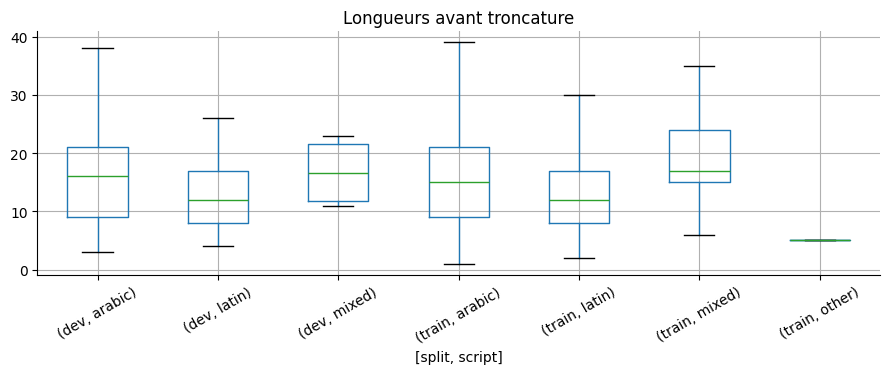

In [10]:
lengths = pd.concat([f.assign(split=s, token_count=f.text.map(lambda t: len(tokens(t))), char_count=f.text.str.len()) for s, f in [("train", train), ("dev", dev)]])
display(lengths.groupby(["split", "script"])[["token_count", "char_count"]].describe())
lengths.boxplot(column="token_count", by=["split", "script"], rot=30, showfliers=False)
plt.suptitle(""); plt.title("Longueurs avant troncature"); plt.tight_layout(); plt.show()

## A.3 · Majorité et raccourci d'écriture

**Objectif :** Construire deux points de comparaison triviaux.

**Méthode et interprétation :** Les majorités sont apprises sur train seulement, puis appliquées à val. Un score script-only élevé révèle une régularité exploitable du corpus, sans démontrer le mécanisme causal des autres modèles.

In [11]:
display(campaign.shortcuts())
display(pd.crosstab(train.script, train.label, normalize="index").reindex(columns=LABELS))

,split,rule,weighted_f1,macro_f1,precision,recall
0,dev,majority,0.211741,0.184480,0.146376,0.382591
1,dev,script_only,0.365609,0.335841,0.321814,0.431174


label,negative,neutral,positive
script,,,
arabic,0.348239,0.292190,0.359571
latin,0.225835,0.522847,0.251318
mixed,0.317073,0.414634,0.268293
other,0.000000,0.000000,1.000000


## A.4 · Entraîner les baselines

**Objectif :** Comparer mots, caractères et combinaison équilibrée.

**Méthode et interprétation :** Mots 1–2 et caractères 2–5 ; LR class_weight=balanced. La combinaison compare C=0.25/1/4 sur val, sur trois graines. Les tokens de ponctuation/emojis sont conservés pour les mots. F2 entraîne aussi union sur une seule écriture.

In [12]:
if RUN_TRAINING:
    campaign.run_part("A", CONFIG)
else:
    print("A non lancé : RUN_TRAINING=False")

[1/24] A_majority_s42
A_majority_s42: dev F1=0.2117, macro=0.1845, 0.4s
[2/24] A_word_s42
A_word_s42: dev F1=0.7399, macro=0.7328, 1.5s
[3/24] A_char_s42
A_char_s42: dev F1=0.7641, macro=0.7609, 9.0s
[4/24] A_union_s42
A_union_s42: dev F1=0.7582, macro=0.7540, 10.0s
[5/24] A_union_C0.25_s42
A_union_C0.25_s42: dev F1=0.7564, macro=0.7505, 5.4s
[6/24] A_union_C4_s42
A_union_C4_s42: dev F1=0.7541, macro=0.7492, 14.2s
[7/24] A_union_train_arabic_s42
A_union_train_arabic_s42: dev F1=0.7092, macro=0.7078, 3.8s
[8/24] A_union_train_latin_s42
A_union_train_latin_s42: dev F1=0.3678, macro=0.3503, 3.0s
[9/24] A_majority_s43
A_majority_s43: dev F1=0.2117, macro=0.1845, 0.4s
[10/24] A_word_s43
A_word_s43: dev F1=0.7399, macro=0.7328, 1.4s
[11/24] A_char_s43
A_char_s43: dev F1=0.7641, macro=0.7609, 9.5s
[12/24] A_union_s43
A_union_s43: dev F1=0.7582, macro=0.7540, 10.0s
[13/24] A_union_C0.25_s43
A_union_C0.25_s43: dev F1=0.7564, macro=0.7505, 4.8s
[14/24] A_union_C4_s43
A_union_C4_s43: dev F1=0.754

## A.5 · Résultats et décision

**Objectif :** Comparer F1 brut et F1 avec règle val.

**Méthode et interprétation :** La règle multiclasse est argmax(log(p_c)+b_c), premier décalage fixé à zéro. Les 25 couples de décalages sont choisis sur val ; le gain val n'est pas une évaluation indépendante.

,family,variant,weighted_f1,macro_f1,std,graines,secondes
0,A,char,0.764076,0.760866,0.0,3,9.451774
2,A,union,0.758243,0.754003,0.0,3,10.097754
3,A,union_C0.25,0.756367,0.750476,0.0,3,4.869827
4,A,union_C4,0.754140,0.749166,0.0,3,14.468856
5,A,word,0.739903,0.732829,0.0,3,1.409381
1,A,majority,0.211741,0.184480,0.0,3,0.408167


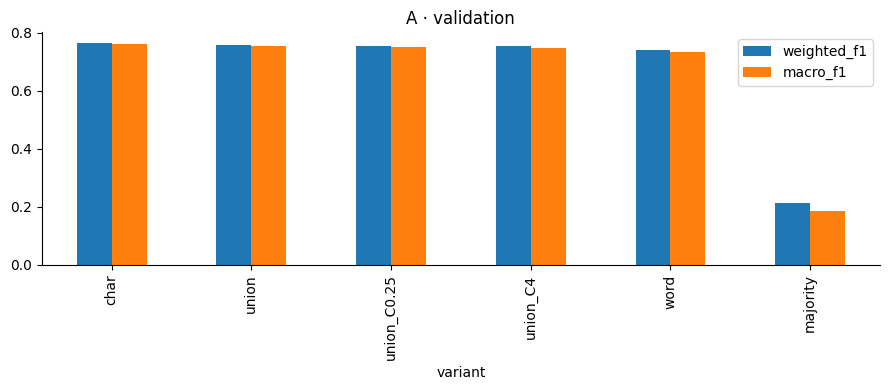

,variant,seed,decision,weighted_f1,macro_f1
0,majority,42,argmax,0.211741,0.184480
1,majority,42,dev_offsets,0.211741,0.184480
2,word,42,argmax,0.726077,0.719517
3,word,42,dev_offsets,0.739903,0.732829
4,char,42,argmax,0.756371,0.754337
5,char,42,dev_offsets,0.764076,0.760866
6,union,42,argmax,0.741830,0.737845
7,union,42,dev_offsets,0.758243,0.754003
8,union_C0.25,42,argmax,0.748537,0.743958
9,union_C0.25,42,dev_offsets,0.756367,0.750476


In [13]:
a_summary = dev_summary("A")
display(a_summary)
if not a_summary.empty:
    a_summary.set_index("variant")[["weighted_f1", "macro_f1"]].plot.bar(title="A · validation")
    plt.tight_layout(); plt.show()
rows = results_table()
if not rows.empty:
    display(rows.loc[rows.family.eq("A") & rows.split.eq("dev"), ["variant", "seed", "decision", "weighted_f1", "macro_f1"]])

## B.1 · Transfert sans entraînement local

**Objectif :** Exécuter les trois NLI et CAMeLBERT.

**Méthode et interprétation :** Modèle NLI imposé : MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7. B2 : CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment. Leurs poids restent fixes ; tous auront des scores test après verrouillage.

In [14]:
if RUN_TRAINING:
    campaign.run_part("B", CONFIG)

[1/4] B_nli_ar_s42


tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.3M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/436M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/436M [00:00<?, ?B/s]

B_camelbert_s42: dev F1=0.6023, macro=0.6011, 0.0s


## B.2 · Hypothèses NLI

**Objectif :** Expliquer comment une classe devient une hypothèse.

**Méthode et interprétation :** Chaque tweet est une prémisse appariée à trois hypothèses. Le modèle utilise les logits d'entailment ; l'auto-attention traite conjointement les deux textes. Trois formulations sont testées, une par langue ; ce n'est pas une étude de paraphrases à langue constante.

In [15]:
from src.models import HYPOTHESES
display(pd.DataFrame(HYPOTHESES, index=LABELS))
display(dev_summary("B"))

,ar,fr,en
negative,هذا النص يعبر عن شعور سلبي.,Ce texte exprime un sentiment négatif.,This text expresses a negative sentiment.
neutral,هذا النص محايد عاطفيا.,Ce texte exprime un sentiment neutre.,This text expresses a neutral sentiment.
positive,هذا النص يعبر عن شعور إيجابي.,Ce texte exprime un sentiment positif.,This text expresses a positive sentiment.


,family,variant,weighted_f1,macro_f1,std,graines,secondes
0,B,camelbert,0.602343,0.601148,NaN,1,0.0
1,B,nli_ar,0.501026,0.507860,NaN,1,0.0
3,B,nli_fr,0.497245,0.502694,NaN,1,0.0
2,B,nli_en,0.463444,0.471246,NaN,1,0.0


## B.3 · Sensibilité et écritures

**Objectif :** Comparer les décisions et les sous-groupes sur val.

**Méthode et interprétation :** Les écarts après réglage intègrent formulation et décalages. CAMeLBERT n'est pas un modèle Arabizi : mesurer plutôt que supposer sa couverture. Une absence de contamination externe ne peut pas être certifiée.

,variant,decision,weighted_f1,macro_f1
48,nli_ar,argmax,0.397959,0.416555
49,nli_ar,dev_offsets,0.501026,0.507860
50,nli_fr,argmax,0.397980,0.418004
51,nli_fr,dev_offsets,0.497245,0.502694
52,nli_en,argmax,0.386009,0.404032
53,nli_en,dev_offsets,0.463444,0.471246
54,camelbert,argmax,0.585340,0.584989
55,camelbert,dev_offsets,0.602343,0.601148


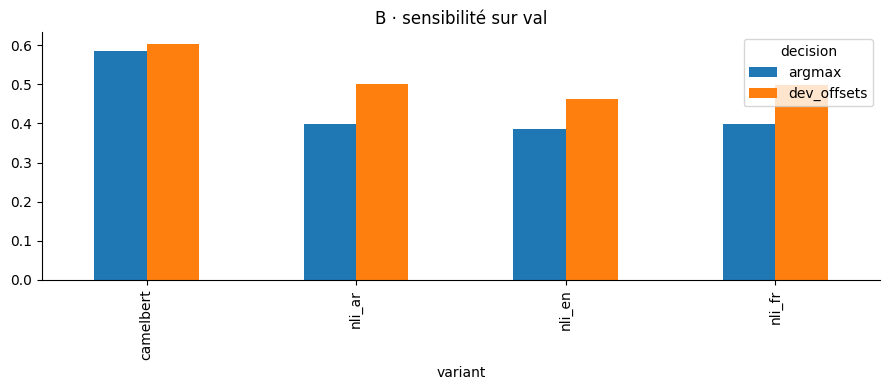

,script,weighted_f1,macro_f1,precision,recall,run
0,arabic,0.643094,0.623097,0.677994,0.660650,B_camelbert_s42_dev_tuned
1,latin,0.372783,0.240257,0.592347,0.530516,B_camelbert_s42_dev_tuned
2,mixed,0.333333,0.444444,0.250000,0.500000,B_camelbert_s42_dev_tuned


,script,weighted_f1,macro_f1,precision,recall,run
0,arabic,0.536438,0.515885,0.564249,0.548736,B_nli_ar_s42_dev_tuned
1,latin,0.456751,0.443716,0.470105,0.455399,B_nli_ar_s42_dev_tuned
2,mixed,0.333333,0.444444,0.250000,0.500000,B_nli_ar_s42_dev_tuned


,script,weighted_f1,macro_f1,precision,recall,run
0,arabic,0.501189,0.469947,0.523890,0.537906,B_nli_en_s42_dev_tuned
1,latin,0.402963,0.367399,0.457443,0.389671,B_nli_en_s42_dev_tuned
2,mixed,0.333333,0.444444,0.250000,0.500000,B_nli_en_s42_dev_tuned


,script,weighted_f1,macro_f1,precision,recall,run
0,arabic,0.520803,0.490476,0.540039,0.552347,B_nli_fr_s42_dev_tuned
1,latin,0.428506,0.375613,0.450363,0.436620,B_nli_fr_s42_dev_tuned
2,mixed,0.333333,0.444444,0.250000,0.500000,B_nli_fr_s42_dev_tuned


In [16]:
rows = results_table()
if not rows.empty:
    b = rows.loc[rows.family.eq("B") & rows.split.eq("dev")]
    display(b[["variant", "decision", "weighted_f1", "macro_f1"]])
    b.pivot(index="variant", columns="decision", values="weighted_f1").plot.bar(title="B · sensibilité sur val")
    plt.tight_layout(); plt.show()
    for path in sorted((ROOT / "results").glob("B_*_dev_tuned.csv")):
        p = pd.read_csv(path)
        display(pd.DataFrame([{"script": s, **campaign.metric_scores(g.label, g.prediction)} for s, g in p.groupby("script")]).assign(run=path.stem))

## C.1 · Vocabulaire et OOV

**Objectif :** Construire le vocabulaire uniquement sur train.

**Méthode et interprétation :** Fréquence minimale 2 ; PAD=0 et UNK=1. Pour fastText v2, les UNK disposent de vecteurs composés par sous-mots, sans apprendre de vocabulaire ou de paramètres sur val/test. Cela ne garantit pas qu'ils représentent bien le sentiment.

In [17]:
vocab = build_vocab(train.text, min_freq=2)
display(pd.DataFrame(encode_texts(train.text.head().tolist(), vocab, CONFIG["max_length"])[:, :15]))
from src.preprocess import oov_table
display(oov_table({"train": train, "dev": dev}, vocab))
print("Taille du vocabulaire :", len(vocab))

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,1033,327,873,1,261,1210,1,1,908,1574,2602,1,1,0,0
1,1017,1,1,1396,830,1174,1406,1,1576,317,1244,481,1476,1234,649
2,236,1,3737,1,1,3622,12,3411,236,4934,7289,4803,5394,1,3981
3,6071,2966,4927,5633,5,0,0,0,0,0,0,0,0,0,0
4,1,1,236,5027,4081,7052,1,6340,3731,7203,1,1,4760,3083,3951


,split,script,tokens,oov_rate
0,train,arabic,51231,0.226991
1,train,latin,29232,0.321155
2,train,mixed,782,0.306905
3,train,other,5,0.600000
4,dev,arabic,4563,0.317554
5,dev,latin,2792,0.414040
6,dev,mixed,67,0.402985


Taille du vocabulaire : 7697


## C.2 · C1, C2, C3 et C4

**Objectif :** Entraîner les réseaux à budget commun.

**Méthode et interprétation :** BiLSTM, BiLSTM-attention maison, Transformer 2 couches / d_model=128 / 4 têtes avec et sans positions ; embeddings aléatoires, AraVec et fastText. Char-CNN utilise son vocabulaire de caractères. Maximum 15 époques et early stopping sur val ; trois graines.

In [18]:
if RUN_TRAINING:
    campaign.run_part("C", CONFIG)

[1/39] C_bilstm_random_s42
  epoch 1/15 loss=0.8531 dev=0.6760
  epoch 2/15 loss=0.5169 dev=0.7329
  epoch 3/15 loss=0.3249 dev=0.7442
  epoch 4/15 loss=0.2067 dev=0.7349
  epoch 5/15 loss=0.1453 dev=0.7149
  epoch 6/15 loss=0.1069 dev=0.7324
C_bilstm_random_s42: dev F1=0.7555, macro=0.7513, 15.5s
[2/39] C_bilstm_fasttext_s42
  epoch 1/15 loss=0.7903 dev=0.6624
  epoch 2/15 loss=0.6164 dev=0.7427
  epoch 3/15 loss=0.4777 dev=0.7192
  epoch 4/15 loss=0.3712 dev=0.7419
  epoch 5/15 loss=0.2872 dev=0.7276
C_bilstm_fasttext_s42: dev F1=0.7530, macro=0.7468, 19.4s
[3/39] C_bilstm_aravec_s42
  epoch 1/15 loss=0.7765 dev=0.7053
  epoch 2/15 loss=0.5492 dev=0.7308
  epoch 3/15 loss=0.3913 dev=0.7436
  epoch 4/15 loss=0.2692 dev=0.7165
  epoch 5/15 loss=0.1860 dev=0.7123
  epoch 6/15 loss=0.1360 dev=0.7224
C_bilstm_aravec_s42: dev F1=0.7549, macro=0.7503, 38.2s
[4/39] C_attention_random_s42
  epoch 1/15 loss=0.8466 dev=0.6693
  epoch 2/15 loss=0.4903 dev=0.7201
  epoch 3/15 loss=0.2985 dev=0.75

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


  epoch 1/15 loss=1.0014 dev=0.4783
  epoch 2/15 loss=0.6603 dev=0.6979
  epoch 3/15 loss=0.4518 dev=0.7353
  epoch 4/15 loss=0.2591 dev=0.6957
  epoch 5/15 loss=0.1427 dev=0.7103
  epoch 6/15 loss=0.1073 dev=0.6959
C_transformer_random_s42: dev F1=0.7432, macro=0.7386, 11.9s
[8/39] C_transformer_random_nopos_s42
  epoch 1/15 loss=0.7465 dev=0.7313
  epoch 2/15 loss=0.4285 dev=0.7128
  epoch 3/15 loss=0.2426 dev=0.7128
  epoch 4/15 loss=0.1472 dev=0.6811
C_transformer_random_nopos_s42: dev F1=0.7313, macro=0.7238, 8.0s
[9/39] C_transformer_fasttext_s42
  epoch 1/15 loss=0.8223 dev=0.6440
  epoch 2/15 loss=0.6677 dev=0.7167
  epoch 3/15 loss=0.5286 dev=0.7214
  epoch 4/15 loss=0.4051 dev=0.7142
  epoch 5/15 loss=0.2978 dev=0.6872
  epoch 6/15 loss=0.2316 dev=0.6739
C_transformer_fasttext_s42: dev F1=0.7521, macro=0.7485, 14.2s
[10/39] C_transformer_fasttext_nopos_s42
  epoch 1/15 loss=0.7692 dev=0.6580
  epoch 2/15 loss=0.5882 dev=0.7497
  epoch 3/15 loss=0.4289 dev=0.7122
  epoch 4/15 

## C.3 · Architecture, embeddings et positions

**Objectif :** Comparer les variantes et leur variabilité.

**Méthode et interprétation :** Lire moyenne et écart-type sur les trois graines. L'ablation positionnelle compare la même architecture, les mêmes embeddings et le même budget ; le meilleur score isolé ne suffit pas.

,family,variant,weighted_f1,macro_f1,std,graines,secondes
3,C,bilstm_aravec,0.753140,0.748614,0.002150,3,38.300634
4,C,bilstm_fasttext,0.750786,0.745425,0.016148,3,23.794202
5,C,bilstm_random,0.749484,0.745376,0.005167,3,14.994853
9,C,transformer_fasttext,0.748560,0.743787,0.009478,3,13.436276
1,C,attention_fasttext,0.748044,0.742149,0.010787,3,16.479241
10,C,transformer_fasttext_nopos,0.743922,0.738715,0.016005,3,12.624074
0,C,attention_aravec,0.743755,0.738036,0.016793,3,40.079547
2,C,attention_random,0.733440,0.729710,0.016128,3,16.018329
6,C,charcnn_random,0.730284,0.725301,0.007264,3,21.868247
7,C,transformer_aravec,0.729990,0.722139,0.009801,3,39.677717


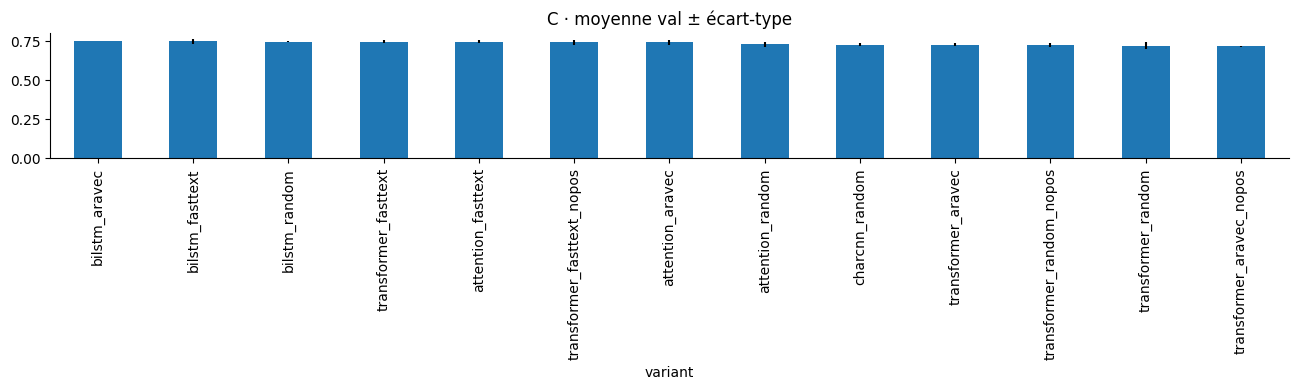

In [19]:
c_summary = dev_summary("C")
display(c_summary)
if not c_summary.empty:
    c_summary.set_index("variant").weighted_f1.plot.bar(yerr=c_summary.set_index("variant")["std"], title="C · moyenne val ± écart-type", figsize=(13, 4))
    plt.tight_layout(); plt.show()

## C.4 · Déséquilibre sur le meilleur C

**Objectif :** Choisir d'abord le meilleur modèle C sur val.

**Méthode et interprétation :** La moyenne des trois graines décide de l'architecture ET des embeddings. On conserve cette référence, puis compare perte pondérée et suréchantillonnage train uniquement. La sélection n'utilise jamais les résultats test.

In [20]:
if RUN_TRAINING:
    display(campaign.choose_c_for_balance())
    campaign.run_part("C_balance", CONFIG)

,family,variant,dev_weighted_f1,dev_macro_f1,seed_std,seeds
13,C,bilstm_aravec,0.753140,0.748614,0.002150,3
14,C,bilstm_fasttext,0.750786,0.745425,0.016148,3
15,C,bilstm_random,0.749484,0.745376,0.005167,3
19,C,transformer_fasttext,0.748560,0.743787,0.009478,3
11,C,attention_fasttext,0.748044,0.742149,0.010787,3
20,C,transformer_fasttext_nopos,0.743922,0.738715,0.016005,3
10,C,attention_aravec,0.743755,0.738036,0.016793,3
12,C,attention_random,0.733440,0.729710,0.016128,3
16,C,charcnn_random,0.730284,0.725301,0.007264,3
17,C,transformer_aravec,0.729990,0.722139,0.009801,3


[1/6] C_bilstm_aravec_weighted_s42
  epoch 1/15 loss=0.7902 dev=0.7173
  epoch 2/15 loss=0.5557 dev=0.7283
  epoch 3/15 loss=0.3969 dev=0.7351
  epoch 4/15 loss=0.2720 dev=0.7187
  epoch 5/15 loss=0.1912 dev=0.7069
  epoch 6/15 loss=0.1326 dev=0.7089
C_bilstm_aravec_weighted_s42: dev F1=0.7434, macro=0.7379, 38.5s
[2/6] C_bilstm_aravec_oversampling_s42
  epoch 1/15 loss=0.7556 dev=0.7072
  epoch 2/15 loss=0.4819 dev=0.7065
  epoch 3/15 loss=0.3661 dev=0.7285
  epoch 4/15 loss=0.2829 dev=0.6915
  epoch 5/15 loss=0.2000 dev=0.7176
  epoch 6/15 loss=0.1466 dev=0.7038
C_bilstm_aravec_oversampling_s42: dev F1=0.7378, macro=0.7334, 38.6s
[3/6] C_bilstm_aravec_weighted_s43
  epoch 1/15 loss=0.7997 dev=0.7025
  epoch 2/15 loss=0.5605 dev=0.7240
  epoch 3/15 loss=0.3874 dev=0.7109
  epoch 4/15 loss=0.2644 dev=0.7239
  epoch 5/15 loss=0.1754 dev=0.7257
  epoch 6/15 loss=0.1164 dev=0.7003
  epoch 7/15 loss=0.0813 dev=0.7134
  epoch 8/15 loss=0.0594 dev=0.7068
C_bilstm_aravec_weighted_s43: dev F1=

## C.5 · Tableau du déséquilibre

**Objectif :** Séparer effet de l'entraînement et effet de la décision.

**Méthode et interprétation :** Le tableau croise sans rééquilibrage, perte pondérée et suréchantillonnage avec argmax brut et règle val. Suréchantillonner avant séparation ferait circuler des copies entre apprentissage et validation.

In [21]:
selection_file = ROOT / "results/c_imbalance_selection.json"
if selection_file.exists():
    base = json.loads(selection_file.read_text(encoding="utf-8"))["variant"]
    rows = results_table()
    balance = rows.loc[rows.family.eq("C") & rows.split.eq("dev") & rows.variant.isin([base, base+"_weighted", base+"_oversampling"])]
    display(balance.groupby(["variant", "decision"]).agg(f1=("weighted_f1", "mean"), macro=("macro_f1", "mean"), std=("weighted_f1", "std")).reset_index())

,variant,decision,f1,macro,std
0,bilstm_aravec,argmax,0.743094,0.738380,0.004255
1,bilstm_aravec,dev_offsets,0.753140,0.748614,0.002150
2,bilstm_aravec_oversampling,argmax,0.733534,0.728866,0.005547
3,bilstm_aravec_oversampling,dev_offsets,0.743941,0.739270,0.005713
4,bilstm_aravec_weighted,argmax,0.731723,0.727152,0.005215
5,bilstm_aravec_weighted,dev_offsets,0.743939,0.739325,0.010445


## C.6 · OOV AraVec et fastText par écriture

**Objectif :** Distinguer absence du lexique et vecteur disponible.

**Méthode et interprétation :** Un mot absent du lexique fastText peut recevoir un vecteur composé par sous-mots ; AraVec ne le compose pas. Les vecteurs AraVec manquants sont initialisés aléatoirement dans le réseau. Ne pas confondre OOV du vocabulaire C et couverture des embeddings.

,split,script,embedding,tokens,lexical_oov_rate,unusable_vector_rate,distinct_oov_with_subword_vector,network_vocab_oov_rate
0,train,arabic,AraVec,51231,0.293943,0.293943,0,0.226991
1,train,arabic,fastText,51231,0.226991,0.000000,11629,0.226991
2,train,latin,AraVec,29232,0.977969,0.977969,0,0.321155
3,train,latin,fastText,29232,0.321155,0.000000,9388,0.321155
4,train,mixed,AraVec,782,0.352941,0.352941,0,0.306905
5,train,mixed,fastText,782,0.306905,0.000000,240,0.306905
6,train,other,AraVec,5,0.200000,0.200000,0,0.600000
7,train,other,fastText,5,0.600000,0.000000,3,0.600000
8,dev,arabic,AraVec,4563,0.266491,0.266491,0,0.317554
9,dev,arabic,fastText,4563,0.317554,0.000000,1393,0.317554


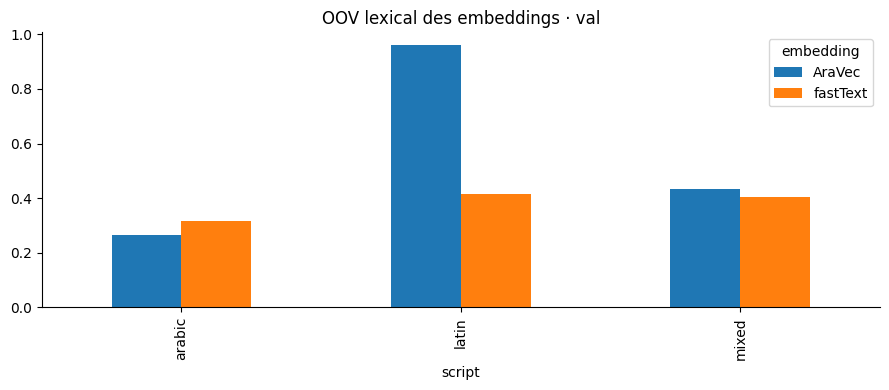

In [22]:
if (ROOT / "results/c_imbalance_selection.json").exists():
    coverage = campaign.embedding_oov(CONFIG)
    display(coverage)
    coverage.loc[coverage.split.eq("dev")].pivot(index="script", columns="embedding", values="lexical_oov_rate").plot.bar(title="OOV lexical des embeddings · val")
    plt.tight_layout(); plt.show()

## C.7 · Attention sur cinq exemples

**Objectif :** Observer de vrais poids d'attention.

**Méthode et interprétation :** Cinq textes val prédéfinis ; meilleure variante d'attention sur val, checkpoint graine42. Chercher emojis, opinion, français, sans transformer ces poids descriptifs en explication causale.

In [23]:
attention_c = attention_examples("C", n=5)
display(attention_c); show_attention(attention_c)

,example,token,attention
0,ary:dev:0,أتمنى,0.000447
1,ary:dev:0,أن,0.002920
2,ary:dev:0,تكون,0.011293
3,ary:dev:0,رأيت,0.019117
4,ary:dev:0,السي,0.026840
...,...,...,...
102,ary:dev:4,el,0.029869
103,ary:dev:4,balada,0.079189
104,ary:dev:4,and,0.186120
105,ary:dev:4,rij3iya,0.242204


## D.1 · DarijaBERT gelé

**Objectif :** Comparer CLS+LR, moyenne+LR et états+BiLSTM-attention.

**Méthode et interprétation :** L'encodeur ne reçoit aucun gradient. La moyenne masque PAD et inclut les tokens spéciaux. L'extraction est mise en cache par données, nettoyage et longueur ; son coût est enregistré séparément.

In [24]:
if RUN_TRAINING:
    campaign.run_part("D", CONFIG)

[1/9] D_cls_s42


tokenizer_config.json:   0%|          | 0.00/307 [00:00<?, ?B/s]

The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.


vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (15 outputs left out)

The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.


  epoch 1/10 loss=0.6990 dev=0.7157
  epoch 2/10 loss=0.5190 dev=0.7201
  epoch 3/10 loss=0.4282 dev=0.7299
  epoch 4/10 loss=0.3604 dev=0.6911
  epoch 5/10 loss=0.3122 dev=0.7090
  epoch 6/10 loss=0.2670 dev=0.7192
D_states_s43: dev F1=0.7385, macro=0.7356, 48.1s
[9/9] D_states_s44


The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.


  epoch 1/10 loss=0.7027 dev=0.7374
  epoch 2/10 loss=0.5202 dev=0.7355
  epoch 3/10 loss=0.4420 dev=0.7455
  epoch 4/10 loss=0.3590 dev=0.7202
  epoch 5/10 loss=0.2970 dev=0.7303
  epoch 6/10 loss=0.2443 dev=0.7266
D_states_s44: dev F1=0.7488, macro=0.7430, 48.0s


## D.2 · Qualité et coût d'apprentissage

**Objectif :** Comparer les trois têtes sur val.

**Méthode et interprétation :** Peu de paramètres entraînables ne signifie pas une inférence peu coûteuse : DarijaBERT reste nécessaire. La latence CPU complète sera mesurée en G, sans cache de représentations.

In [25]:
display(dev_summary("D"))
rows = results_table()
if not rows.empty:
    display(rows.loc[rows.family.eq("D") & rows.split.eq("dev") & rows.decision.eq("dev_offsets"), ["variant", "seed", "train_seconds", "trainable_parameters", "weighted_f1"]])

,family,variant,weighted_f1,macro_f1,std,graines,secondes
2,D,states,0.746022,0.741676,0.006633,3,63.597104
0,D,cls,0.709313,0.705686,0.000000,3,62.029447
1,D,mean,0.691924,0.686239,0.000000,3,37.523573


,variant,seed,train_seconds,trainable_parameters,weighted_f1
147,cls,42,108.194606,2307,0.709313
149,cls,43,38.873696,2307,0.709313
151,cls,44,39.020038,2307,0.709313
153,mean,42,73.173272,2307,0.691924
155,mean,43,18.685576,2307,0.691924
157,mean,44,20.711870,2307,0.691924
159,states,42,94.671018,435715,0.750826
161,states,43,48.141160,435715,0.738454
163,states,44,47.979135,435715,0.748785


## D.3 · Attention D2 sur cinq exemples

**Objectif :** Visualiser les sous-tokens du checkpoint D2.

**Méthode et interprétation :** Les unités sont celles du tokenizer BERT. Les poids sont normalisés et PAD est masqué ; une forte attention sur un emoji ne prouve pas qu'il cause la décision.

In [26]:
attention_d = attention_examples("D", n=5)
display(attention_d); show_attention(attention_d)

The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.
The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.
The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.


,example,token,attention
0,ary:dev:0,[CLS],0.000271
1,ary:dev:0,اتمنى,0.008048
2,ary:dev:0,ان,0.015619
3,ary:dev:0,تكون,0.014899
4,ary:dev:0,رايت,0.017389
...,...,...,...
158,ary:dev:4,##ya,0.036791
159,ary:dev:4,r,0.007805
160,ary:dev:4,##be,0.015356
161,ary:dev:4,##h,0.037978


## E.1 · Protocole de fine-tuning

**Objectif :** Préparer une comparaison équitable.

**Méthode et interprétation :** DarijaBERT et DarijaBERT-Arabizi : AdamW 2e-5, perte pondérée à partir de train, batch effectif 32, maximum 5 époques, minimum 3 avant arrêt anticipé, warmup 10 %, trois graines. Micro-batch 2 et accumulation ; précision mixte sur CUDA et checkpointing de gradients. Les décalages sont choisis sur val après sélection de l'époque.

In [27]:
display(pd.Series({"lr": 2e-5, "batch_effectif": 32, "micro_batch": CONFIG["micro_batch_e"], "epochs": CONFIG["e_epochs"], "warmup": 0.1, "weighted_loss": True, "longueur": CONFIG["max_length"], "seeds": CONFIG["seeds"]}).to_frame("E1/E2"))
print("AraBizi spécialisé peut mieux couvrir le latin ; ce n'est pas un résultat avant mesure.")

,E1/E2
lr,0.00002
batch_effectif,32
micro_batch,2
epochs,5
warmup,0.1
weighted_loss,True
longueur,128
seeds,"[42, 43, 44]"


AraBizi spécialisé peut mieux couvrir le latin ; ce n'est pas un résultat avant mesure.


## E.2 · E1 : deux modèles fine-tunés

**Objectif :** Adapter les poids des encodeurs à ary.

**Méthode et interprétation :** Six runs complets, sans score inventé. Le fine-tuning CPU reste possible mais coûteux. Réduire le micro-batch conserve le batch effectif ; changer un réglage impose un nouveau nom de campagne.

In [28]:
if RUN_TRAINING:
    campaign.run_part("E1", CONFIG)
display(dev_summary("E"))

[1/6] E_darijabert_s42


The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.
The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.
The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


  epoch 1/5 loss=0.7866 dev=0.7192
  epoch 2/5 loss=0.5336 dev=0.7528
  epoch 3/5 loss=0.4229 dev=0.7493
  epoch 4/5 loss=0.3381 dev=0.7509
E_darijabert_s42: dev F1=0.7911, macro=0.7900, 822.3s
[2/6] E_darijabert_s43


The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.
The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.
The `xla_device` argument has been deprecated in v4.4.0 of Transformers. It is ignored and you can safely remove it from your `config.json` file.


KeyboardInterrupt: 

## E.3 · E2 : encodeur partagé, têtes ary/arq

**Objectif :** Mesurer l'apport de la tâche auxiliaire.

**Méthode et interprétation :** L'encodeur est choisi parmi E1 sur val ary. Chaque pas optimise L_ary + λ L_arq, avec pondérations propres aux corpus. λ=0 correspond au run E1 de référence ; λ=0.1/0.3/0.7 sont entraînés sur trois graines, au même nombre de pas ary et budget d'époques. arq n'est utilisé ni en A–D ni pour le test principal. Les collisions textuelles arq/ary sont retirées de l'auxiliaire.

In [ ]:
if CONFIG["include_e2"] and RUN_TRAINING:
    display(campaign.choose_e2_encoder())
    campaign.run_part("E2", CONFIG)
    display(pd.Series(json.loads((ROOT / "results/arq_audit.json").read_text(encoding="utf-8"))).to_frame("Audit arq"))

## E.4 · Effet de λ

**Objectif :** Comparer l'auxiliaire à la référence mono-tâche.

**Méthode et interprétation :** Une tâche proche peut apporter un signal utile ; elle peut aussi introduire un vocabulaire, une distribution ou des gradients défavorables. Le coût E2 inclut les calculs auxiliaires. L'effet observé ne sera pas supposé positif.

In [ ]:
e_summary = dev_summary("E")
display(e_summary)
if not e_summary.empty:
    e_summary.set_index("variant")[["weighted_f1", "macro_f1"]].plot.bar(title="E1/E2 · validation", figsize=(11,4))
    plt.tight_layout(); plt.show()

## E.5 · Courbes d'apprentissage

**Objectif :** Repérer surapprentissage et arrêt anticipé.

**Méthode et interprétation :** Les courbes proviennent des historiques réels. L'époque retenue utilise le F1 val brut ; le réglage des décalages est une étape distincte. Une absence de courbe signifie absence de run.

In [ ]:
for family in "CDE":
    figure = plot_histories(family)
    if figure:
        display(Image(filename=str(figure)))

## Avant F · Contrôle de complétude

**Objectif :** Vérifier qu'aucune expérience obligatoire n'a été omise.

**Méthode et interprétation :** La campagne refuse l'évaluation finale si une partie manque. La reprise d'un notebook déjà verrouillé n'autorise aucun nouvel apprentissage.

In [ ]:
status = campaign.status(CONFIG)
display(status)
status.to_csv(ROOT / "results/execution_status.csv", index=False)
if not results_table().empty:
    display(select_on_dev())

## Frontière val/test · Verrouillage

**Objectif :** Figer les choix avant le test.

**Méthode et interprétation :** Toutes les variantes demandées sont déclarées avant test, avec leur règle val. Le tableau G conserve un représentant par famille choisi sur val. Les comparaisons complètes sont sauvegardées dans results.csv ; le meilleur score test ne remplace jamais le candidat verrouillé.

In [ ]:
if RUN_FINAL_EVALUATION:
    final = campaign.finalize(CONFIG)
    display(final)
else:
    print("F/G non exécutés : RUN_FINAL_EVALUATION=False")

## F1.1 · Distributions val/test et raccourcis

**Objectif :** Mesurer les changements globaux et conditionnels.

**Méthode et interprétation :** Une variation de proportions n'établit pas à elle seule un pur label shift. étudier aussi les écritures et les scores par classe. Les labels test ne sont lus qu'après verrouillage.

In [ ]:
after_test()
display(campaign.distributions(include_test=True))
display(campaign.shortcuts(include_test=True))
shift = show_file("f1_label_shift.csv")
shift.set_index(shift.columns[0]).plot.bar(title="F1 · proportions val/test")
plt.tight_layout(); plt.show()

## F1.2 · F1 en fonction des décalages

**Objectif :** Visualiser la sensibilité a posteriori.

**Méthode et interprétation :** Grille finie de deux décalages relatifs. Le maximum test est un oracle optimiste de diagnostic, jamais une nouvelle décision déployée. Les fichiers meta et le candidat restent intacts.

In [ ]:
after_test()
grid = campaign.threshold_diagnostic()
fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, split in zip(axes, ["dev", "test"]):
    matrix = grid.pivot(index="neutral_offset", columns="positive_offset", values=f"{split}_weighted_f1")
    im = ax.imshow(matrix.to_numpy(), origin="lower", aspect="auto", extent=[-1.5,1.5,-1.5,1.5])
    ax.set(title=f"F1 pondéré · {split} · diagnostic", xlabel="Décalage positif", ylabel="Décalage neutre")
    fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(ROOT / "results/figures/F1_threshold_grid.png", dpi=140); plt.show()
diagnostic = json.loads((ROOT / "results/f1_posthoc_oracle.json").read_text(encoding="utf-8"))
display(pd.Series(diagnostic).to_frame())
curve = grid.loc[np.isclose(grid.positive_offset, diagnostic["frozen_offsets"][2])]
curve.plot(x="neutral_offset", y=["dev_weighted_f1", "test_weighted_f1"], title="F1 = f(décalage neutre), décalage positif figé")
plt.axvline(diagnostic["frozen_offsets"][1], color="black", linestyle="--", label="Décision choisie sur val")
plt.ylabel("Weighted-F1"); plt.legend(); plt.tight_layout()
plt.savefig(ROOT / "results/figures/F1_threshold_curve.png", dpi=140); plt.show()

## F2 · écriture non vue

**Objectif :** Mesurer arabe→latin et latin→arabe.

**Méthode et interprétation :** TF-IDF union est entraîné sur un seul sous-ensemble train, sur trois graines ; les décalages utilisent val. Comparer à l'union train complet sur la même écriture test. Taille du train et couverture d'écriture changent ensemble : l'écart n'isole pas causalement l'alphabet.

In [ ]:
after_test()
cross = show_file("f2_cross_script.csv")
if not cross.empty:
    display(cross.groupby(["train_script", "test_script"]).weighted_f1.agg(["mean", "std"]))
    full = pd.read_csv(ROOT / "results/A_union_s42_scripts.csv")
    display(full.assign(reference="union train complet"))

## F3 · Qualité et couverture par écriture

**Objectif :** Comparer arabe, latin et mixte.

**Méthode et interprétation :** Le faible effectif mixte limite les conclusions. La translittération est optionnelle et n'est pas ajoutée sans système validé. Les embeddings ne sont pas ajustés sur test pour produire ce rapport.

In [ ]:
after_test()
display(campaign.embedding_oov(CONFIG, include_test=True))
lock = json.loads((ROOT / "results/selection_lock.json").read_text(encoding="utf-8"))
for winner in lock["selected_variants"]:
    show_file(f"{winner['family']}_{winner['variant']}_s42_scripts.csv")

## F4 · Retirer emojis et ponctuation répétée

**Objectif :** Mesurer les bascules après perturbation.

**Méthode et interprétation :** Uniquement tweets polarisés initialement corrects ; les cas réellement modifiés sont dénombrés. Pour chacun, toute bascule devient une erreur. Les sous-ensembles différent par modèle et ne permettent pas un classement causal de robustesse.

In [ ]:
after_test()
comparison = pd.read_csv(ROOT / "results/comparison.csv")
robustness = pd.DataFrame([{**json.loads(r.robustness_f4), "family": r.family} for r in comparison.dropna(subset=["robustness_f4"]).itertuples()])
display(robustness)
if not robustness.empty:
    robustness.set_index("family").flip_rate_changed.plot.bar(title="F4 · taux d'erreur après perturbation, cas modifiés")
    plt.tight_layout(); plt.show()
show_file("f4_perturbations.csv", 8)

## F5 · Graines, IC et McNemar

**Objectif :** Décrire la variabilité d'entraînement et d'échantillonnage.

**Méthode et interprétation :** IC percentile 95 % par 1 000 bootstrap de tweets, conditionnel au checkpoint 42. L'écart-type sur trois graines mesure autre chose. McNemar exact compare les erreurs appariées des deux meilleures variantes choisies sur val ; ce n'est pas un test direct de différence de F1.

In [ ]:
after_test()
comparison = pd.read_csv(ROOT / "results/comparison.csv")
display(campaign.uncertainty_table())
display(comparison[["family", "variant", "weighted_f1", "ci_low", "ci_high", "test_seed_mean", "test_seed_std", "n_seeds", "bootstrap"]])
display(pd.Series(json.loads((ROOT / "results/f5_mcnemar.json").read_text(encoding="utf-8"))).to_frame("McNemar"))
plt.errorbar(comparison.family, comparison.weighted_f1, yerr=[(comparison.weighted_f1-comparison.ci_low).clip(lower=0), (comparison.ci_high-comparison.weighted_f1).clip(lower=0)], fmt="o", capsize=4)
plt.ylabel("Weighted-F1 test et IC bootstrap 95 %"); plt.tight_layout(); plt.show()

## F6.1 · Dossier de trente erreurs

**Objectif :** Lire et classer les erreurs du candidat fixé sur val.

**Méthode et interprétation :** Catégories suggérées : ironie, graphies/tokenisation Arabizi, mélange français, neutre/polarisé, annotation. Les heuristiques sont des hypothèses ; chaque ligne nécessite une lecture humaine. Le désaccord de votes n'est pas une preuve de bruit.

In [ ]:
after_test()
errors = show_file("f6_30_erreurs.csv", 30)
display(campaign.error_review_summary())
print("Fichier à compléter :", ROOT / "results/f6_30_erreurs.csv")

## F6.2 · Valider la revue

**Objectif :** Séparer propositions automatiques et conclusions humaines.

**Méthode et interprétation :** Compléter categorie_humaine, validation_humaine='validé' et commentaire_humain dans le CSV. Relancer cette cellule pour lire votre revue. L'échantillonnage diversifié ne mesure pas la fréquence des catégories dans toutes les erreurs ; ne pas extrapoler sa part de bruit.

In [ ]:
after_test()
review = pd.read_csv(ROOT / "results/f6_30_erreurs.csv", keep_default_na=False)
display(campaign.error_review_summary())
if "categorie_humaine" in review:
    validated = review.loc[review.validation_humaine.eq("validé")]
    display(validated.categorie_humaine.value_counts().to_frame("erreurs validées de cet échantillon"))

## G.1 · Tableau final et matrice de confusion

**Objectif :** Choisir en tenant compte de qualité, coût et limites.

**Méthode et interprétation :** Le candidat a déjà été fixé sur val. Les colonnes montrent temps d'apprentissage, extraction partagée éventuelle, latence CPU après échauffement, taille des poids, paramètres, robustesse et écritures. Aucun changement de candidat après observation du test.

In [ ]:
after_test()
final = show_file("comparison.csv")
all_variants = show_file("comparison_all_variants.csv", 100)
display(Image(filename=str(ROOT / "results/figures/modele_final.png")))
print("Candidat fixé sur val :", lock["candidate"])

## G.2 · Compromis qualité/coût

**Objectif :** Présenter les résultats de manière visuelle.

**Méthode et interprétation :** Les temps et latences dépendent du matériel. La mesure CPU utilise 30 inférences unitaires, après chargement et échauffement. La taille inclut les ressources nécessaires à l'inférence ; elle n'est pas une mesure de RAM de pic.

In [ ]:
after_test()
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, x, title in zip(axes, ["cpu_ms_per_tweet", "weight_mb", "train_seconds"], ["Latence CPU (ms/tweet)", "Poids (Mio)", "Apprentissage (s)"]):
    positive = final.loc[final[x].gt(0)]
    ax.scatter(positive[x], positive.weighted_f1)
    for r in positive.itertuples():
        ax.annotate(r.family, (getattr(r,x), r.weighted_f1))
    ax.set(xlabel=title, ylabel="Weighted-F1 test", xscale="log")
plt.tight_layout(); plt.savefig(ROOT / "results/figures/G_quality_cost.png", dpi=140); plt.show()

## G.3 · Préparer l'oral Q1–Q12

**Objectif :** Relier chaque réponse à une mesure réelle.

**Méthode et interprétation :** Présenter d'abord protocole et corpus, puis baselines, représentations, adaptation, robustesse et choix pratique. Pour chaque question : observation → mesure → interprétation → limite. Les sources et les questions officielles sont disponibles dans research/.

In [ ]:
questions = PROJECT / "research/questions_officielles.md"
if questions.exists():
    display(Markdown(questions.read_text(encoding="utf-8")))
checklist = {"Q1–Q2": "A + distributions + shortcut_baselines.csv", "Q3": "nettoyage conservateur + F4 ; aucune ablation individuelle du français/Arabizi n'est revendiquée", "Q4–Q5": "B, résultats val/test et scripts", "Q6–Q7": "C, déséquilibre sur meilleur C et ablation des positions", "Q8": "D vs E1, temps/paramètres et écritures", "Q9": "E2, lambda=0 (E1) vs 0.1/0.3/0.7", "Q10": "F1, décision val et oracle grille test séparé", "Q11": "F2/F3 et compromis des deux écritures", "Q12": "F6 validé humainement et tableau G"}
display(pd.Series(checklist).to_frame("Preuves à commenter"))
print("Un score ne devient un résultat qu'après exécution. Ne pas présenter de gain non mesuré.")

## Conclusion à rédiger après exécution

1. Quel modèle gagne sur val, puis que montre son test ? Indiquer moyenne, graines et IC.
2. Quel compromis observe-t-on entre arabe, latin et mixte ?
3. E1 dépasse-t-il D ? E2 améliore-t-il E1 et pour quel λ choisi sur val ?
4. Quelle part des 30 erreurs a été validée humainement ? Quelles limites persistent ?
5. Quel modèle convient au domaine de déploiement envisagé, avec quels besoins de suivi ?

**Extensions facultatives non réalisées ici :** MARBERTv2, translittération, cibles souples à partir des votes.
La suppression isolée du français, des chiffres Arabizi et des répétitions n'est pas évaluée par F4 ;
la réponse complète à Q3 exigerait ces ablations distinctes. Ne pas inventer leurs effets.

**Provenance des anciens scores :** notebook `_historique` et anciens `results/` ; aucune sortie historique
n'est une mesure de cette campagne. L'application et le PPTX historiques ne sont pas mis à jour automatiquement.